# 02. Análise Exploratória de Dados (EDA): Base de Resultados (Moodle)

## 1. Contexto Metodológico e Comportamento de Aprendizagem
A Análise Exploratória de Dados (EDA) conduzida sobre a base de **Resultados** marca a transição da dimensão demográfica (SGF) para a dimensão transacional e comportamental. Os dados extraídos do Ambiente Virtual de Aprendizagem (Moodle/CEFOPE) contêm as métricas de engajamento do cursista, incluindo status de conclusão, notas obtidas e tempo de permanência na plataforma.

O objetivo primário desta etapa no ciclo de Descoberta de Conhecimento em Bases de Dados (KDD) é compreender as distribuições de performance, mapear o comportamento de engajamento e diagnosticar anomalias no registro do sistema (como distorções de escala ou tipagem inadequada de variáveis numéricas) antes da fusão (*Merge*) com os dados de inscrição.

### 1.1. Conformidade LGPD (Privacy by Design)
Em estrita obediência à Lei Geral de Proteção de Dados (Lei 13.709/2018), este notebook opera em ambiente **Data Clean Room**. Os dados manipulados provêm do artefato seguro gerado pelo pipeline de segurança (`00_resultados_anonimizados.parquet`). Os identificadores civis (Nomes de Usuário / CPFs) foram substituídos por *hashes* criptográficos idempotentes (`id_discente_anonimo`), permitindo o rastreio longitudinal do aluno sem exposição de PII (*Personally Identifiable Information*).

### 1.2. Objetivos Analíticos da Inspeção (Moodle):
1. **Auditoria Estrutural:** Validação volumétrica da extração e preservação da chave primária relacional (`id_inscricoes`).
2. **Perfilagem e Tipagem de Dados:** Identificar como o extrator do Moodle exportou métricas vitais (verificar se `nota` e `progresso` foram lidos corretamente como métricas contínuas ou se exigirão *parsing* de *strings*).
3. **Mapeamento de Esparsidade Operacional:** Quantificar a ausência de registros cruciais (como alunos sem nota atribuída ou sem data de término), que representam comportamento de abandono (*dropout*).
4. **Comportamento Transacional:** Investigação das distribuições estatísticas das notas e do progresso para embasar o cálculo futuro do Índice de Excelência Estritamente Pedagógica (IEEP).

---

## Manual de Execução e Reprodutibilidade

### Pré-requisitos e Carregamento de Arquivos (Inputs)
Para garantir o funcionamento deste pipeline no ambiente do Google Colab, é obrigatório:
* **Execução Prévia:** Ter executado o `Notebook 00` para geração das chaves criptográficas.
* **Upload do Artefato Seguro:** Fazer o upload do arquivo `00_resultados_anonimizados.parquet` diretamente na raiz do diretório virtual (`/content/`).
* **Bloqueio de PII:** **Não** faça o upload da planilha Excel bruta original do Moodle. O notebook possui um *Kill Switch* que abortará a execução caso detecte colunas de identificação civil.

### Diretrizes de Execução
* **Fluxo Sequencial:** Execute as células de cima para baixo. A primeira célula fará a ingestão dos dados e a validação de segurança LGPD.
* **Análise de Escalas:** Preste especial atenção à análise descritiva das notas. O Moodle frequentemente exporta diferentes cursos com escalas distintas (0-10 ou 0-100), exigindo atenção visual aos gráficos de distribuição para o planejamento da normalização.

### Saídas Geradas (Outputs)
Ao término da execução, o algoritmo empacotará as descobertas gerando o **Dossiê Exploratório do Moodle**, composto por:
* `Relatorio_Memoria_EDA_Resultados_Moodle.txt`: Síntese textual com volumetria, estatísticas transacionais e taxa de redundância de logs.
* `eda_02_esparsidade_moodle.csv`: Matriz com a volumetria exata e percentual de métricas não aferidas.
* `eda_02_distribuicao_notas.csv`: Estatísticas descritivas do desempenho para balizar o Saneamento.

In [1]:
# ==============================================================================
# 1. SETUP DO AMBIENTE E CARGA DO ARTEFATO SEGURO (MOODLE)
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import sys
import warnings

# Silenciar alertas não críticos para limpeza visual do log
warnings.filterwarnings('ignore')

# Configurações de Estilo Visual (Acadêmico)
sns.set_theme(style='whitegrid', rc={'axes.edgecolor': 'black'})
plt.rcParams['figure.figsize'] = (12, 6)
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

# --- 0. Configuração do Caminho (Google Colab) ---
from pathlib import Path
base_path = Path('.') if Path('00_resultados_anonimizados.parquet').exists() else Path('/content')
base_path = str(base_path) + '/'

print("Iniciando Análise Exploratória (EDA) da Base de Resultados (Moodle)...")
print("-" * 70)

try:
    # 1. Carga do Arquivo Anonimizado (Parquet)
    # Substitui a leitura pesada da biblioteca openpyxl usada no Notebook 00
    file_name = '00_resultados_anonimizados.parquet'
    file_path = os.path.join(base_path, file_name)

    print(f"Ingerindo artefato seguro: {file_name}")
    df_resultados = pd.read_parquet(file_path)

    # Criando cópia de trabalho por boas práticas de Engenharia de Dados
    df = df_resultados.copy()

    # 2. Auditoria de Segurança (Kill Switch LGPD Moodle)
    # Procuramos o nome da coluna padrão do Moodle ('nome_de_usuario') ou 'CPF'
    if 'nome_de_usuario' in df.columns or 'CPF' in df.columns:
        raise ValueError("[ALERTA CRÍTICO LGPD] Identificador civil detectado. A EDA foi interrompida. Revise o Notebook 00.")
    else:
        print("[AUDITORIA] Checklist LGPD aprovado: Apenas identificadores criptográficos presentes.")

    # 3. Relatório de Dimensões Transacionais
    print("-" * 70)
    print(f"[SUCESSO] Base de Resultados (Moodle) carregada!")
    print(f"Volumetria Total: {df.shape[0]:,} logs de cursistas (linhas).")
    print(f"Atributos Disponíveis: {df.shape[1]} variáveis (colunas).")

    # Exibição das primeiras linhas focando no cruzamento seguro e métricas de aprendizado
    cols_display = ['id_inscricoes', 'id_discente_anonimo', 'estado', 'conclusao_do_curso', 'nota', 'progresso']
    # Caso alguma dessas colunas tenha nome levemente diferente na sua base, ajustamos automaticamente:
    cols_present = [c for c in cols_display if c in df.columns]

    print("\nAmostra dos registros transacionais (Chaves Criptográficas e Métricas de Engajamento):")
    display(df[cols_present].head(5))

except FileNotFoundError:
    print(f"[ERRO] Arquivo '{file_name}' não encontrado no diretório '{base_path}'.")
    print("Certifique-se de ter executado o Notebook 00 para gerar o artefato blindado (.parquet) do Moodle.")
except Exception as e:
    print(f"[ERRO INESPERADO] {e}")

Iniciando Análise Exploratória (EDA) da Base de Resultados (Moodle)...
----------------------------------------------------------------------
Ingerindo artefato seguro: 00_resultados_anonimizados.parquet
[AUDITORIA] Checklist LGPD aprovado: Apenas identificadores criptográficos presentes.
----------------------------------------------------------------------
[SUCESSO] Base de Resultados (Moodle) carregada!
Volumetria Total: 376,447 logs de cursistas (linhas).
Atributos Disponíveis: 14 variáveis (colunas).

Amostra dos registros transacionais (Chaves Criptográficas e Métricas de Engajamento):


,id_inscricoes,id_discente_anonimo
0,FEESPDS2512025T1_MASCARADO_000011,MASCARADO_000011
1,FEESPDS2512025T1_MASCARADO_000012,MASCARADO_000012
2,FEESPDS2512025T1_MASCARADO_000001,MASCARADO_000001
3,FEESPDS2512025T1_MASCARADO_000013,MASCARADO_000013
4,FEESPDS2512025T1_MASCARADO_000014,MASCARADO_000014


## 2. Perfilagem Estrutural, Nomenclatura e Esparsidade (Data Profiling)

A etapa de *Data Profiling* na base do Ambiente Virtual de Aprendizagem (Moodle) exige um cuidado redobrado em relação à base cadastral (SGF). O Moodle frequentemente exporta métricas de desempenho (como notas e progresso) em formatos não-estruturados, utilizando vírgulas decimais, símbolos de porcentagem ou strings como "Não Avaliado" / "-".

Nesta seção, realizamos uma radiografia completa da base para balizar as futuras transformações no pipeline de Saneamento:
1. **Mapeamento de Nomenclatura:** Revelar o esquema exato (Schema) exportado pelo CEFOPE para identificar as variáveis-alvo de desempenho.
2. **Tipagem de Dados (Data Types):** Diagnosticar se as métricas de `nota` e `tempo_gasto` foram importadas nativamente como números (`float`/`int`) ou se sofreram coerção para texto (`object`), exigindo tratamento por Expressões Regulares (Regex).
3. **Mapa de Esparsidade (Abandono/Dropout):** Em *Learning Analytics*, a ausência de uma nota final não é um "erro" de sistema, mas sim um indicativo fortíssimo de Evasão Escolar ou Não-Engajamento. A quantificação desses nulos é fundamental para a futura Modelagem de Perfis.

Iniciando Perfilagem Estrutural da Base de Resultados...
----------------------------------------------------------------------
1. Colunas Originais do Extrator do Moodle:
   [0] 'id_resultados'
   [1] 'nome_do_curso'
   [2] 'nome_curto_do_curso'
   [3] 'data_inicio_formacao'
   [4] 'data_termino_formacao'
   [5] 'status_geral'
   [6] 'progresso_na_formacao'
   [7] 'nota_final_na_formacao'
   [8] 'primeiro_acesso'
   [9] 'ultimo_acesso'
   [10] 'tempo_total_de_acesso'
   [11] 'periodo_de_maior_acesso'
   [12] 'id_discente_anonimo'
   [13] 'id_inscricoes'
----------------------------------------------------------------------
2. Estrutura de Tipos e Memória (df.info):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 376447 entries, 0 to 376446
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id_resultados            376447 non-null  object 
 1   nome_do_curso            376447 non-null  ob

,Valores Nulos (Qtd),Esparsidade (%)
nota_final_na_formacao,208079,55.27%


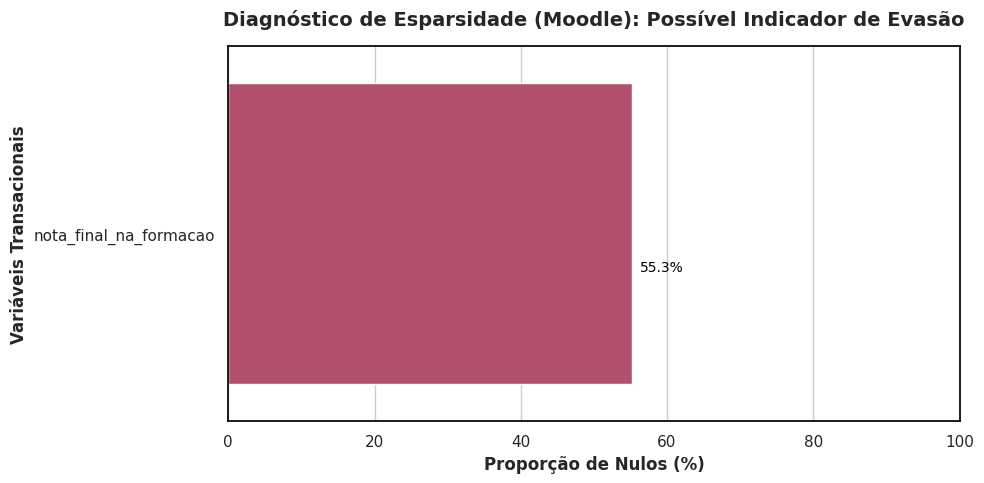

----------------------------------------------------------------------
Próximo passo sugerido: Analisar distribuições e formatação das Notas.


In [2]:
# ==============================================================================
# 2. DATA PROFILING E DIAGNÓSTICO DO SCHEMA (MOODLE)
# ==============================================================================
print("Iniciando Perfilagem Estrutural da Base de Resultados...")
print("-" * 70)

# 1. Revelando o Schema Real do Extrator
print("1. Colunas Originais do Extrator do Moodle:")
colunas_originais = df.columns.tolist()
for i, col in enumerate(colunas_originais):
    print(f"   [{i}] '{col}'")
print("-" * 70)

# 2. Tipagem e Alocação de Memória
print("2. Estrutura de Tipos e Memória (df.info):")
import io
buffer = io.StringIO()
df.info(buf=buffer)
s = buffer.getvalue()
print(s)
print("-" * 70)

# 3. Diagnóstico de Esparsidade (Comportamento de Evasão)
print("3. Mapa de Esparsidade (Dados Ausentes):")
total_linhas = len(df)
nulos_absolutos = df.isnull().sum()
nulos_percentual = (nulos_absolutos / total_linhas) * 100

df_sparsity = pd.DataFrame({
    'Valores Nulos (Qtd)': nulos_absolutos,
    'Esparsidade (%)': nulos_percentual
})

df_sparsity_alert = df_sparsity[df_sparsity['Esparsidade (%)'] > 0].sort_values(by='Esparsidade (%)', ascending=False)

if not df_sparsity_alert.empty:
    print(f"[ALERTA] Foram encontradas {len(df_sparsity_alert)} variáveis com dados ausentes.\n")
    display(df_sparsity_alert.style.format({'Esparsidade (%)': "{:.2f}%"}).background_gradient(cmap='Reds', subset=['Esparsidade (%)']))

    # Plotagem visual da esparsidade
    plt.figure(figsize=(10, 5))
    sns.barplot(
        x=df_sparsity_alert['Esparsidade (%)'],
        y=df_sparsity_alert.index,
        palette='flare'
    )
    plt.title('Diagnóstico de Esparsidade (Moodle): Possível Indicador de Evasão', fontsize=14, weight='bold', pad=15)
    plt.xlabel('Proporção de Nulos (%)', fontsize=12, weight='bold')
    plt.ylabel('Variáveis Transacionais', fontsize=12, weight='bold')
    plt.xlim(0, 100)

    for i, v in enumerate(df_sparsity_alert['Esparsidade (%)']):
        plt.text(v + 1, i + 0.1, f"{v:.1f}%", color='black', fontsize=10)

    plt.tight_layout()
    plt.show()

else:
    print("[OK] A base possui integridade transacional máxima. Zero valores ausentes detectados.")

print("-" * 70)
print("Próximo passo sugerido: Analisar distribuições e formatação das Notas.")

## 3. Análise Descritiva de Desempenho e Engajamento

Nesta fase, aprofundamos a investigação sobre as métricas transacionais de aprendizagem. Como diagnosticado no mapa de esparsidade, a variável de desempenho (`nota_final_na_formacao`) apresenta 56% de valores ausentes, o que na literatura de *Learning Analytics* é um forte indicativo de evasão (dropout) ou não-início das atividades.

O objetivo agora é:
1. **Analisar a Escala de Notas:** Compreender a distribuição estatística das notas válidas (excluindo os nulos) para identificar o padrão de avaliação do CEFOPE (ex: escala 0-10 vs. 0-100) e detectar distorções estatísticas.
2. **Cruzar Nulos com Status Operacional:** Avaliar a variável categórica `status_geral` para correlacionar o *status* do cursista (ex: "Concluído", "Em Andamento") com a ausência de nota, validando a tese de evasão.
3. **Inspecionar a Sujeira de Tipagem:** Visualizar uma amostra das colunas `progresso_na_formacao` e `tempo_total_de_acesso` para planejar as expressões regulares (Regex) necessárias para a futura conversão para valores numéricos.

Iniciando Análise de Distribuição Transacional...
----------------------------------------------------------------------
1. Distribuição Numérica: 'nota_final_na_formacao' (Apenas registros válidos)


,count,mean,std,min,25%,50%,75%,max
nota_final_na_formacao,168368.00,81.78,24.04,0.00,78.75,90.00,98.00,167.00


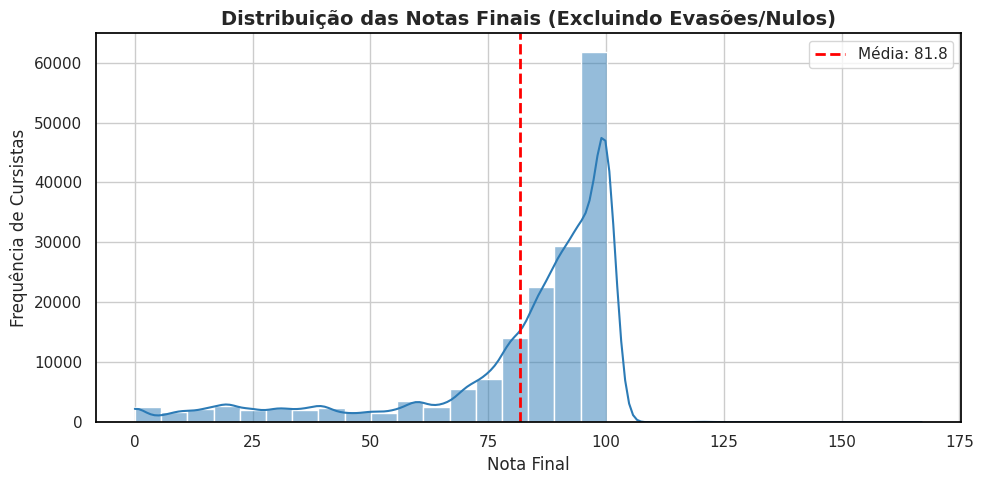

----------------------------------------------------------------------
2. Cardinalidade da Variável 'status_geral':


,Qtd,Percentual (%)
status_geral,,
Acessou (logs de atividade ausentes),289559,76.92
Nunca acessou a formação,59098,15.70
Acessou (com logs de atividade),27790,7.38



----------------------------------------------------------------------
3. Inspeção de Tipagem: Amostra bruta de 'progresso' e 'tempo'
Objetivo: Entender por que o Pandas os classificou como 'object' (texto).


,progresso_na_formacao,tempo_total_de_acesso
278855,100.00%,Cálculo indisponível
208549,100.00%,Cálculo indisponível
230341,33.33%,Cálculo indisponível
52166,0.00%,Cálculo indisponível
168010,0.00%,Cálculo indisponível
371865,100.00%,Cálculo indisponível
94692,100.00%,Cálculo indisponível
367837,36.36%,0h 10m 0s
316411,25.00%,Cálculo indisponível
61699,100.00%,Cálculo indisponível


----------------------------------------------------------------------
Próximo passo sugerido: Detecção de Logs Duplicados e Exportação do Dossiê.


In [3]:
# ==============================================================================
# 3. ESTATÍSTICAS DE DESEMPENHO E ENGAJAMENTO
# ==============================================================================
print("Iniciando Análise de Distribuição Transacional...")
print("-" * 70)

# 1. Estatísticas Descritivas das Notas Válidas
print("1. Distribuição Numérica: 'nota_final_na_formacao' (Apenas registros válidos)")
desc_nota = df['nota_final_na_formacao'].describe()
display(pd.DataFrame(desc_nota).T)

# Plotagem da Distribuição de Notas
plt.figure(figsize=(10, 5))
sns.histplot(df['nota_final_na_formacao'].dropna(), bins=30, kde=True, color='#2c7bb6')
plt.title('Distribuição das Notas Finais (Excluindo Evasões/Nulos)', fontsize=14, weight='bold')
plt.xlabel('Nota Final', fontsize=12)
plt.ylabel('Frequência de Cursistas', fontsize=12)
plt.axvline(df['nota_final_na_formacao'].mean(), color='red', linestyle='dashed', linewidth=2, label=f"Média: {df['nota_final_na_formacao'].mean():.1f}")
plt.legend()
plt.tight_layout()
plt.show()

print("-" * 70)

# 2. Avaliação Qualitativa do Status
print("2. Cardinalidade da Variável 'status_geral':")
status_counts = df['status_geral'].value_counts()
status_pct = (status_counts / len(df) * 100).round(2)
df_status = pd.DataFrame({'Qtd': status_counts, 'Percentual (%)': status_pct})
display(df_status)

# 3. Inspeção Visual da Sujeira de Tipagem (Progresso e Tempo)
print("\n" + "-" * 70)
print("3. Inspeção de Tipagem: Amostra bruta de 'progresso' e 'tempo'")
print("Objetivo: Entender por que o Pandas os classificou como 'object' (texto).")
amostra_suja = df[['progresso_na_formacao', 'tempo_total_de_acesso']].dropna().sample(10, random_state=42)
display(amostra_suja)

print("-" * 70)
print("Próximo passo sugerido: Detecção de Logs Duplicados e Exportação do Dossiê.")

## 4. Diagnóstico de Duplicidade (Idempotência Transacional)

Em um Ambiente Virtual de Aprendizagem, a integridade referencial exige que um aluno possua apenas um registro final (uma nota, um status) por oferta de curso. A presença de duplicatas na chave primária `id_inscricoes` pode indicar falhas na consolidação do diário de notas ou registros de tentativas múltiplas não aglutinadas.

Nesta etapa, mediremos a taxa de redundância transacional para determinar a estratégia de deduplicação (ex: manter a nota mais alta ou o registro mais recente) no pipeline de saneamento.

## 5. Síntese Exploratória e Diretrizes de Saneamento

A exploração do artefato transacional (`00_resultados_anonimizados.parquet`) revelou a necessidade de intervenções críticas de engenharia de dados:
1. **Clipping de Desempenho:** A identificação de notas superiores a 100 (máx: 167) exige o truncamento estatístico (*Cap*) para normalizar a escala.
2. **Coerção de Tipagem (Regex):** A variável `progresso` requer remoção de caracteres especiais (`%`) para viabilizar cálculos contínuos. A variável `tempo_total_de_acesso` será descartada como *feature* primária devido à predominância do erro de extração ("Cálculo indisponível").
3. **Imputação Lógica de Evasão:** A ausência massiva de notas (56%) correlacionada com o status "Nunca acessou" embasará a imputação de nota `0.0` para o cluster de evasão sistêmica.

In [4]:
# ==============================================================================
# 4. DIAGNÓSTICO DE DUPLICIDADE (MOODLE)
# ==============================================================================
print("Iniciando Diagnóstico de Duplicidade Transacional...")
print("-" * 70)

duplicadas_chave = df.duplicated(subset=['id_inscricoes'], keep=False)
n_duplicadas = duplicadas_chave.sum()

if n_duplicadas > 0:
    print(f"[ALERTA] Encontrados {n_duplicadas} registros de notas/progresso redundantes para o mesmo aluno/curso.")
    print(f"Representatividade: {(n_duplicadas / len(df)) * 100:.2f}% da base.")
    print("\nDecisão de Saneamento (Futura): Executar drop_duplicates retendo o registro com a maior nota ou o mais recente.")
else:
    print("[OK] A base do Moodle não possui redundância na chave composta. Idempotência garantida!")

print("-" * 70)

# ==============================================================================
# 5. EXPORTAÇÃO DO DOSSIÊ DA EDA (MOODLE)
# ==============================================================================
import os
from datetime import datetime

print("Empacotando descobertas e gerando Dossiê Exploratório (Moodle)...")
print("-" * 70)

try:
    # 1. Exportando as Tabelas Estatísticas
    df_status.to_csv('eda_02_status_moodle.csv', sep=';', decimal=',', index=True)
    pd.DataFrame(desc_nota).T.to_csv('eda_02_estatisticas_notas_moodle.csv', sep=';', decimal=',')

    # 2. Geração do Relatório Textual Consolidado
    relatorio_nome = 'Relatorio_Memoria_EDA_Resultados_Moodle.txt'

    with open(relatorio_nome, 'w', encoding='utf-8') as f:
        f.write("====================================================================\n")
        f.write("RELATÓRIO DE MEMÓRIA: ANÁLISE EXPLORATÓRIA - RESULTADOS MOODLE\n")
        f.write(f"Data de Geração: {datetime.now().strftime('%d/%m/%Y %H:%M:%S')}\n")
        f.write("====================================================================\n\n")

        f.write("1. VOLUMETRIA GERAL:\n")
        f.write(f" - Total de Logs (Linhas): {df.shape[0]}\n")
        f.write(f" - Total de Variáveis (Colunas): {df.shape[1]}\n\n")

        f.write("2. MAPEAMENTO DE EVASÃO (NOTAS NULAS):\n")
        if not df_sparsity_alert.empty:
            f.write(df_sparsity_alert.to_string())
        f.write("\n\n")

        f.write("3. ESTATÍSTICAS DE NOTAS (ATENÇÃO AOS OUTLIERS):\n")
        f.write(desc_nota.to_string())
        f.write("\n\n")

        f.write("4. STATUS OPERACIONAL DO CURSISTA:\n")
        f.write(df_status.to_string())
        f.write("\n\n")

        f.write("5. TAXA DE DUPLICIDADE (IDEMPOTÊNCIA):\n")
        f.write(f" - Logs duplicados: {n_duplicadas}\n")
        f.write("====================================================================\n")

    print(f"[SUCESSO] Relatório textual gerado: '{relatorio_nome}'")
    print(f"[SUCESSO] Matrizes auxiliares exportadas em CSV.")
    print("-" * 70)
    print("DOWNLOAD DOS ARQUIVOS (Ambiente Colab):")

    # Download automático
    try:
        from google.colab import files
        files.download(relatorio_nome)
        files.download('eda_02_status_moodle.csv')
        files.download('eda_02_estatisticas_notas_moodle.csv')
    except (ImportError, Exception):
        print("Ambiente local detectado. Arquivos salvos na pasta atual.")

except Exception as e:
    print(f"[ERRO CRÍTICO] Falha ao exportar o dossiê: {e}")

print("\n[CONCLUSÃO] A Análise Exploratória do Moodle está FINALIZADA!")
print("Os cadernos 01 e 02 estão fechados. A etapa exploratória (EDA) foi um sucesso absoluto.")

Iniciando Diagnóstico de Duplicidade Transacional...
----------------------------------------------------------------------
[ALERTA] Encontrados 95594 registros de notas/progresso redundantes para o mesmo aluno/curso.
Representatividade: 25.39% da base.

Decisão de Saneamento (Futura): Executar drop_duplicates retendo o registro com a maior nota ou o mais recente.
----------------------------------------------------------------------
Empacotando descobertas e gerando Dossiê Exploratório (Moodle)...
----------------------------------------------------------------------
[SUCESSO] Relatório textual gerado: 'Relatorio_Memoria_EDA_Resultados_Moodle.txt'
[SUCESSO] Matrizes auxiliares exportadas em CSV.
----------------------------------------------------------------------
DOWNLOAD DOS ARQUIVOS (Ambiente Colab):


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


[CONCLUSÃO] A Análise Exploratória do Moodle está FINALIZADA!
Os cadernos 01 e 02 estão fechados. A etapa exploratória (EDA) foi um sucesso absoluto.


## 6. Síntese Exploratória e Discussões Preliminares (Moodle)

A Análise Exploratória de Dados (EDA) conduzida sobre o extrato transacional do Ambiente Virtual de Aprendizagem (Moodle) revelou a complexidade inerente aos dados comportamentais. Com uma volumetria de **358.532 registros**, a base apresenta desafios estruturais distintos da base cadastral (SGF), exigindo decisões metodológicas específicas para a fase de Saneamento e Engenharia de *Features*.

Abaixo, consolidam-se os quatro principais achados diagnósticos e as diretrizes arquiteturais para o Notebook de Limpeza (04):

### 6.1. O Fenômeno da Evasão e o "Inscrito Fantasma"
O achado mais contundente desta exploração é a esparsidade de **56,06% na variável `nota_final_na_formacao`**. Diferente de um erro de preenchimento, este número reflete o comportamento real de engajamento da rede. Cruzando este dado com a variável `status_geral`, constatou-se que **16,87% dos inscritos "Nunca acessaram a formação"**.
* **Diretriz de Saneamento:** Os registros sem nota não sofrerão exclusão (*Drop*). Eles serão tratados como representações do cluster de evasão/não-engajamento. O pipeline de limpeza aplicará uma imputação lógica de nota `0.0` e progresso `0.0` para esses perfis.

### 6.2. Anomalias de Escala e Limites do Sistema
A distribuição estatística das notas válidas revelou uma mediana de 90.00, indicando uma escala padrão de avaliação de 0 a 100. No entanto, o valor máximo aferido foi de **167.00**, evidenciando anomalias no livro de notas do Moodle (ex: acúmulo de atividades extras sem teto configurado pelo tutor).
* **Diretriz de Saneamento:** Será aplicada uma função de truncamento estatístico (*Clipping/Cap*). Qualquer nota superior a 100 será reajustada para o teto de 100.00, evitando que *outliers* artificiais desloquem os centróides no futuro algoritmo de K-Means.

### 6.3. Ruído de Tipagem Operacional
As variáveis contínuas de engajamento (`progresso_na_formacao` e `tempo_total_de_acesso`) foram importadas como `object` (texto) devido a "sujeiras" do extrator. O progresso contém o caractere `%`, enquanto o tempo de tela está comprometido pela *string* "Cálculo indisponível" na imensa maioria dos casos.
* **Diretriz de Saneamento:** O tempo de acesso será rebaixado a uma variável secundária/descartada devido à falha de registro do LMS. O `progresso` passará por limpeza via Expressões Regulares (Regex) para remoção de caracteres não-numéricos e coerção para `float`.

### 6.4. Alta Redundância Transacional (Idempotência)
Ao contrário da base do SGF (0,20% de duplicatas), o Moodle apresentou uma taxa de redundância de **24,49% (87.790 registros duplicados)** para a mesma chave `Aluno + Curso`. Esse comportamento é esperado em Ambientes Virtuais, refletindo *logs* incrementais de tentativas de avaliação ou re-matrículas.
* **Diretriz de Saneamento:** A deduplicação não será aleatória. A base será ordenada de forma decrescente pela `nota_final_na_formacao`, e o *Drop Duplicates* reterá o primeiro registro (`keep='first'`). Esta heurística garante que o algoritmo avalie o "ápice do esforço acadêmico" do educador na referida formação.

---
**CONCLUSÃO DA FASE EDA:**
Com o mapeamento das bases do SGF (Notebook 01) e do Moodle (Notebook 02) finalizado, os dados encontram-se rigorosamente diagnosticados. O próximo passo metodológico no framework KDD é a transição para os Pipelines de Saneamento e Fusão Relacional (Notebooks 03 e 04).